## Data Exploration

In this notebook we study the dataset and look for the demographic groups we want to seperate and focus on. Additionally, we check for any cleaning that may be needed on the original dataset (null or duplicate entries).

In [1]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the dataset
cdc_diabetes = fetch_ucirepo(id=891)

# Seperate features and target
x = cdc_diabetes.data.features
y = cdc_diabetes.data.targets

# Combine into one dataframe
df = pd.concat([x,y], axis=1)

# Save original downloaded data
df.to_csv("../data/raw/diabetes_health_indicators.csv", index=False)

In [2]:
# Check to make sure dataset was loaded properly
print("Dataset dimensions:", df.shape)

# Display the first few records
display(df.head())

Dataset dimensions: (253680, 22)


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


In [3]:
# Names of all the columns
print("\nColumn names:")
print(df.columns.tolist())


Column names:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']


In [4]:
# Display key information about dataset
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype
---  ------                --------------   -----
 0   HighBP                253680 non-null  int64
 1   HighChol              253680 non-null  int64
 2   CholCheck             253680 non-null  int64
 3   BMI                   253680 non-null  int64
 4   Smoker                253680 non-null  int64
 5   Stroke                253680 non-null  int64
 6   HeartDiseaseorAttack  253680 non-null  int64
 7   PhysActivity          253680 non-null  int64
 8   Fruits                253680 non-null  int64
 9   Veggies               253680 non-null  int64
 10  HvyAlcoholConsump     253680 non-null  int64
 11  AnyHealthcare         253680 non-null  int64
 12  NoDocbcCost           253680 non-null  int64
 13  GenHlth               253680 non-null  int64
 14  MentHlth              253680 non-null  int64
 15  PhysHlth              253680 non-n

None

,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
count,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,...,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000,253680.000000
mean,0.429001,0.424121,0.962670,28.382364,0.443169,0.040571,0.094186,0.756544,0.634256,0.811420,...,0.084177,2.511392,3.184772,4.242081,0.168224,0.440342,8.032119,5.050434,6.053875,0.139333
std,0.494934,0.494210,0.189571,6.608694,0.496761,0.197294,0.292087,0.429169,0.481639,0.391175,...,0.277654,1.068477,7.412847,8.717951,0.374066,0.496429,3.054220,0.985774,2.071148,0.346294
min,0.000000,0.000000,0.000000,12.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,0.000000,0.000000,1.000000,24.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,6.000000,4.000000,5.000000,0.000000
50%,0.000000,0.000000,1.000000,27.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,8.000000,5.000000,7.000000,0.000000
75%,1.000000,1.000000,1.000000,31.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,...,0.000000,3.000000,2.000000,3.000000,0.000000,1.000000,10.000000,6.000000,8.000000,0.000000
max,1.000000,1.000000,1.000000,98.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,5.000000,30.000000,30.000000,1.000000,1.000000,13.000000,6.000000,8.000000,1.000000


In [5]:
# Distribution of Diabetes 0(no diabetes) and 1(prediabetes or diabetes)
print("\nTarget distribution:")
print(df["Diabetes_binary"].value_counts())


Target distribution:
Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64


,Age,Income,Education,Sex
mean,8.032119,6.053875,5.050434,0.440342
median,8.000000,7.000000,5.000000,0.000000
std,3.054220,2.071148,0.985774,0.496429


Age
1      5700
2      7598
3     11123
4     13823
5     16157
6     19819
7     26314
8     30832
9     33244
10    32194
11    23533
12    15980
13    17363
Name: count, dtype: int64

Feature Proportions:
 Age
1     0.022469
2     0.029951
3     0.043847
4     0.054490
5     0.063690
6     0.078126
7     0.103729
8     0.121539
9     0.131047
10    0.126908
11    0.092766
12    0.062993
13    0.068444
Name: count, dtype: float64

Income
1     9811
2    11783
3    15994
4    20135
5    25883
6    36470
7    43219
8    90385
Name: count, dtype: int64

Feature Proportions:
 Income
1    0.038675
2    0.046448
3    0.063048
4    0.079372
5    0.102030
6    0.143764
7    0.170368
8    0.356295
Name: count, dtype: float64

Education
1       174
2      4043
3      9478
4     62750
5     69910
6    107325
Name: count, dtype: int64

Feature Proportions:
 Education
1    0.000686
2    0.015937
3    0.037362
4    0.247359
5    0.275583
6    0.423072
Name: count, dtype: float64

Sex
0    141974
1

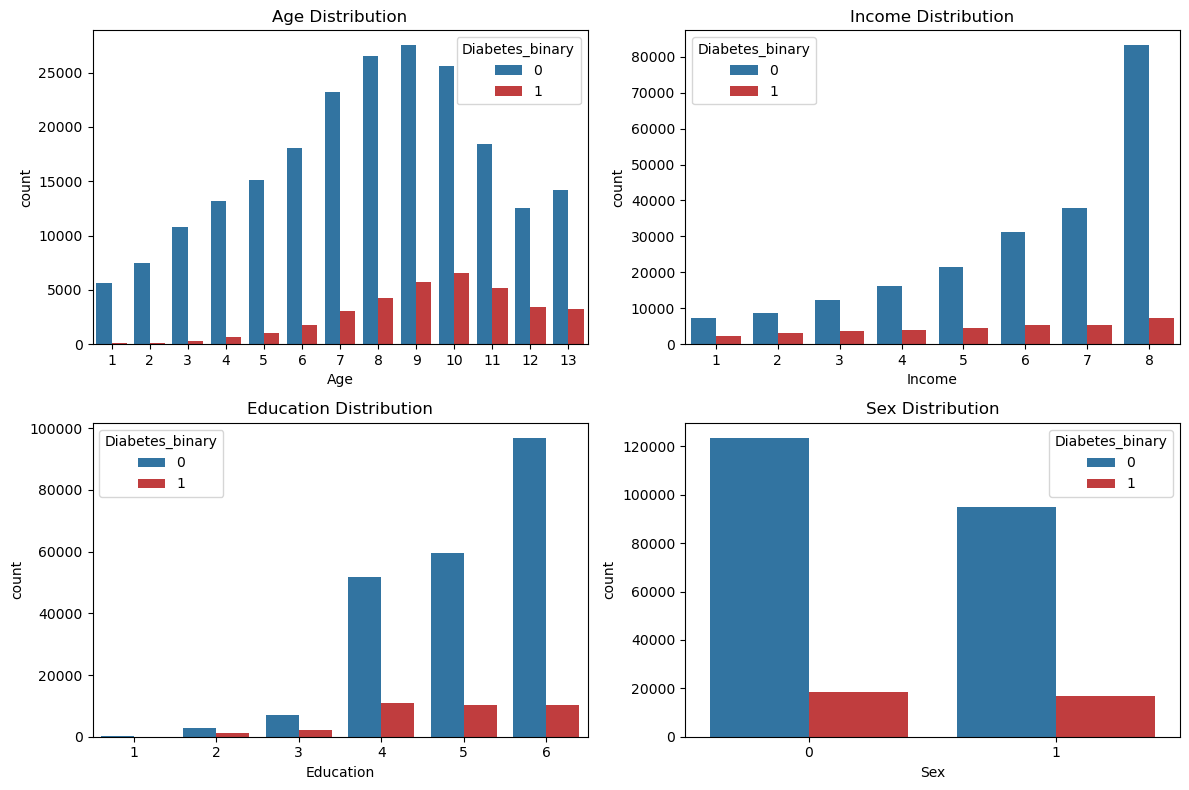

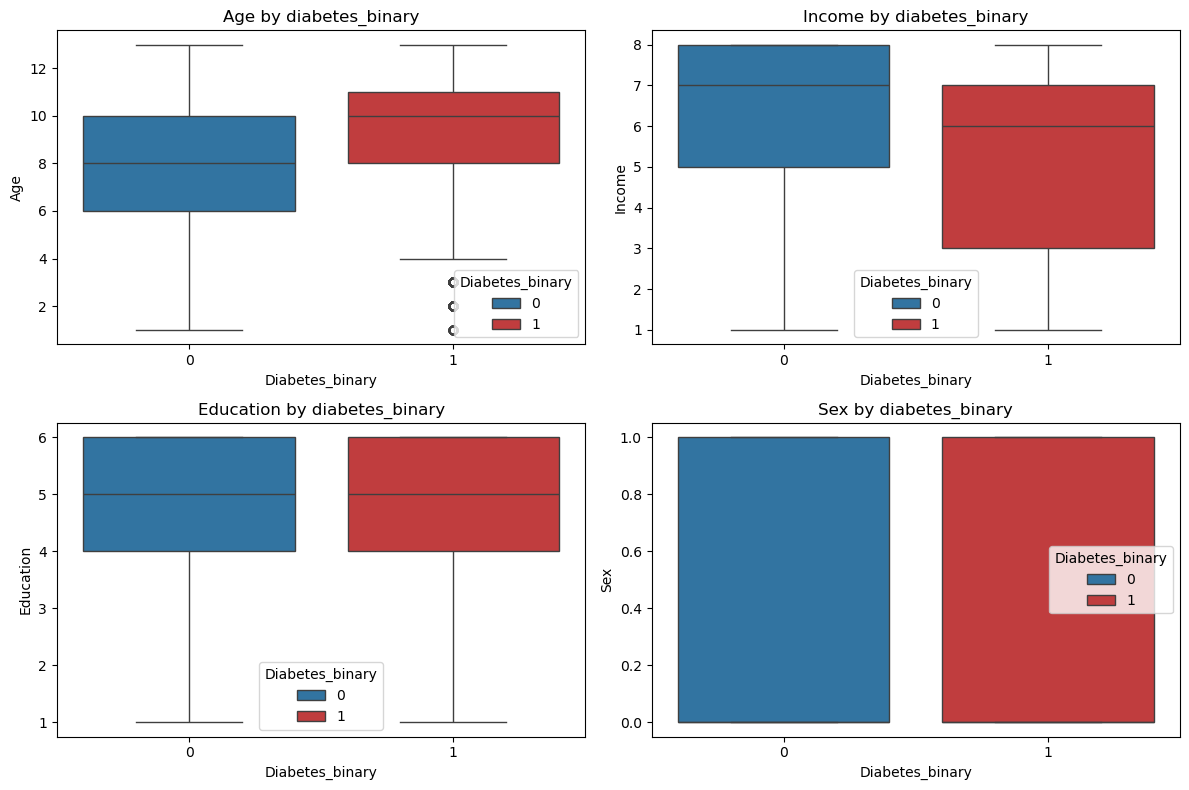

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

demographic_features = ["Age", "Income", "Education", "Sex"]
display(df[demographic_features].agg(["mean", "median", "std"]))

# Check feature balance
for feature in demographic_features:
    feature_counts = df[feature].value_counts().sort_index()
    print(feature_counts)
    print("\nFeature Proportions:\n", (feature_counts / len(df)))
    print()
# Check target balance
target_counts = df["Diabetes_binary"].value_counts().sort_index()
print(target_counts)
print("\nProportions:\n", (target_counts / len(df)))

# Visualize feature distributions
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(demographic_features, axes.ravel()):
    sns.countplot(data=df, x=feature, hue="Diabetes_binary", ax=ax, palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(f"{feature} Distribution")
plt.tight_layout()
plt.show()

# Check feature outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for feature, ax in zip(demographic_features, axes.ravel()):
    sns.boxplot(data=df, x="Diabetes_binary", hue="Diabetes_binary", y=feature, ax=ax, palette={0: "tab:blue", 1: "tab:red"})
    ax.set_title(f"{feature} by diabetes_binary")
plt.tight_layout()
plt.show()

In [7]:
# Make the dataframes for 4 social econoimic groups. Check if there is sufficient data in each of these subgroups to be able train good models.

# Age groups
# Note: UCI uses these categories for age -> 13-level age category
#      1 = 18-24, 2 = 25-29, 3 = 30-34 
#      4 = 35-39, 5 = 40-44, etc. up to 13 = 80 or older

df["Age_Groups"] = pd.cut(
    df["Age"],
    bins=[0, 4, 8, 13],                                                     # Here our bins represent Younger Adults (18-39), Middle Age (40-59), Older (60+)
    labels=["Younger Adult", "Middle Age", "Older"],
)

# Income Groups
# Note: UCI uses these categories for income -> 8-level income category
#      1 = <$10,000, 2 = $10,000-$15,000, 3 = $15,000-$20,000 
#      4 = $20,000-$25,000, 5 = $25,000-$30,000, etc. up to 8 = $75,000 or more

df["Income_Groups"] = pd.cut(
    df["Income"],
    bins=[0, 3, 6, 8],                                                       # Here our bins represent Lower Income (<$10,000-$20,000), Middle Income ($20,000-$35,000), Higher Income ($35,000+)
    labels=["Lower Income", "Middle Income", "Higher Income"],
)


# Education Groups
# Note: UCI uses these categories for education -> 6-level education category
#      1 = No school or kindergarden, 2 = Grades 1-8, 3 = Grades 9-11 
#      4 = Grade 12 or GED (High school graduate), 5 = College 1-3 years, 6 = College >4 years

df["Education_Groups"] = pd.cut(
    df["Education"],
    bins=[0, 3, 4, 6],                                                      # Here our bins represent <HS, HS Graduate, >HS 
    labels=["Below High School", "High School", "Some College or Higher"],
)


# Sex labels
df["Sex_Group"] = df["Sex"].map({
    0: "Female",
    1: "Male"
})

In [8]:
# Here we examine the size and diabetes distribution of each group

demographic_columns = [
    "Sex_Group",
    "Age_Groups",
    "Income_Groups",
    "Education_Groups"
]

for column in demographic_columns:
    print(f"\n {column} ")

    summary = df.groupby(column, observed=False)["Diabetes_binary"].agg(
        Total="count",                                                              # Total number of people in each group
        Diabetes_Cases="sum",                                                       # Number of people with prediabetes/diabetes
        Diabetes_Rate="mean",                                                       # Percentage of each group w/ diabetes                                                    
    )

    summary["Diabetes_Rate"] *= 100

    display(summary.round(2))




 Sex_Group 


,Total,Diabetes_Cases,Diabetes_Rate
Sex_Group,,,
Female,141974,18411,12.97
Male,111706,16935,15.16



 Age_Groups 


,Total,Diabetes_Cases,Diabetes_Rate
Age_Groups,,,
Younger Adult,38244,1158,3.03
Middle Age,93122,10144,10.89
Older,122314,24044,19.66



 Income_Groups 


,Total,Diabetes_Cases,Diabetes_Rate
Income_Groups,,,
Lower Income,37588,9037,24.04
Middle Income,82488,13849,16.79
Higher Income,133604,12460,9.33



 Education_Groups 


,Total,Diabetes_Cases,Diabetes_Rate
Education_Groups,,,
Below High School,13695,3526,25.75
High School,62750,11066,17.64
Some College or Higher,177235,20754,11.71


From these results, we can see that these 4 social demographics have a good distribution and number of observations. All 4 groups have enough data to and interesting differences within subgroup diabetes rates to motivate the investigation of each independently. Furthermore, We continue by cleaning any unecessary data from the dataset.

In [9]:
# Check for missing values
print("Missing values:")
display(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Check data types
print("\nData types:")
display(df.dtypes)

Missing values:


HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
Diabetes_binary         0
Age_Groups              0
Income_Groups           0
Education_Groups        0
Sex_Group               0
dtype: int64


Duplicate rows: 24206

Data types:


HighBP                     int64
HighChol                   int64
CholCheck                  int64
BMI                        int64
Smoker                     int64
Stroke                     int64
HeartDiseaseorAttack       int64
PhysActivity               int64
Fruits                     int64
Veggies                    int64
HvyAlcoholConsump          int64
AnyHealthcare              int64
NoDocbcCost                int64
GenHlth                    int64
MentHlth                   int64
PhysHlth                   int64
DiffWalk                   int64
Sex                        int64
Age                        int64
Education                  int64
Income                     int64
Diabetes_binary            int64
Age_Groups              category
Income_Groups           category
Education_Groups        category
Sex_Group                 object
dtype: object

There are no missing values to clean. All the data types are stored as integers, wither as binary variables or categorical variables translated to discrete numbers. Note that although we have duplicate entries, we leave them for two main reasons:
1. They represent different respondents who happen to have identical responses to all of their survey questions; they are not erroneous records
2. Removing them would would also reduce our dataset size greatly and change the representation of certain responses.